In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
np.random.seed(10)

In [30]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

In [31]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [32]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [33]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [34]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [35]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_f1, hist_wagi, epoki, test=False):
    if (test):
        # Wykres F1
        plt.figure(figsize=(10, 4))
        plt.plot(range(epoki), hist_f1, color='red')
        plt.title('Wzrost F1 w kolejnych epokach')
        plt.xlabel('Epoka')
        plt.ylabel('F1-score')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

    # Wykresy dopasowania
    y_train_true = np.argmax(y_train, axis=1) if y_train.ndim > 1 else y_train
    y_train_pred = np.argmax(y_pred_train, axis=1) if y_pred_train.ndim > 1 else y_pred_train
    
    y_test_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test
    y_test_pred = np.argmax(y_pred_test, axis=1) if y_pred_test.ndim > 1 else y_pred_test

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    def wykres_dopasowania(ax, X_dane, y_prawda, y_predykcja, tytul):
        margines = 0.1
        x_min, x_max = X_dane[:, 0].min() - margines, X_dane[:, 0].max() + margines
        y_min, y_max = X_dane[:, 1].min() - margines, X_dane[:, 1].max() + margines
        
        rozdzielczosc = 400
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdzielczosc),
                             np.linspace(y_min, y_max, rozdzielczosc))
        siatka = np.c_[xx.ravel(), yy.ravel()]
        
        # TŁO - prawdziwe wartości
        odleglosci = cdist(siatka, X_dane)
        najblizsze_idx = np.argmin(odleglosci, axis=1)
        
        Z_true = y_prawda[najblizsze_idx]
        Z_true = Z_true.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z_true, alpha=0.3, cmap='viridis')
        
        # KROPKI - przewidziane wartości przez model
        ax.scatter(X_dane[:, 0], X_dane[:, 1], c=y_predykcja, cmap='viridis', edgecolor='k', alpha=0.9, s=50)
        
        ax.set_title(tytul)
        ax.set_xlabel('Cecha X')
        ax.set_ylabel('Cecha Y')

    wykres_dopasowania(axes[0], X_train, y_train_true, y_train_pred, 'Trening (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')
    wykres_dopasowania(axes[1], X_test, y_test_true, y_test_pred, 'Test (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')

    plt.tight_layout()
    plt.show()

In [36]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, funkcja_straty=Crossentropy, test=False, test_F1=False):
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    
    # Inicjalizacja historii F1
    hist_f1 = []

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]

            # Przejście dla batcha
            y_pred_batch = model.forward(X_batch)

            # Obliczenie straty dla batcha
            loss = strata.forward(y_pred_batch, y_batch)

            # Wsteczna propagacja i aktualizacja wag
            grad_output = strata.backward()
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Obliczanie F1 TRENINGOWEGO co epokę dla wykresu
        y_pred_all = model.forward(X_train_scaled)
        f1_treningowe = f1(y_train, y_pred_all)
        hist_f1.append(f1_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_F1:
                y_pred_test = model.forward(X_test_scaled)
                f1_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | F1 Trening: {f1_treningowe:>8.4f} | F1 Test: {f1_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | F1 Trening: {f1_treningowe:>8.4f}")

    print("-" * 50)
    print(f"F1 treningowe FINALNE: {hist_f1[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    f1_test = f1(y_test, y_pred_test_final)
    print(f"F1 testowe FINALNE: {f1_test:.4f}")

    wykresy(X_train, y_train, X_test, y_test, y_pred_all, y_pred_test_final, hist_f1, hist_wagi, epoki, test)

    return hist_f1

In [37]:
def wykres_f1(hist_softmax, hist, zbior):
    plt.figure(figsize=(10, 5))

    plt.plot(hist, label='Sigmoid', color='#ff6b6b', linewidth=2)

    plt.plot(hist_softmax, label='Softmax', color='#4ecdc4', linewidth=2)

    plt.title(f'Porównanie zbieżności F1-Score ({zbior})', fontsize=14)
    plt.xlabel('Epoka', fontsize=12)
    plt.ylabel('F1-Score (Trening)', fontsize=12)

    plt.legend(fontsize=12, loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [38]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

# Dane rings3-regular

In [39]:
rings3_regular_test = pd.read_csv("mio1/classification/rings3-regular-test.csv")
rings3_regular_train = pd.read_csv("mio1/classification/rings3-regular-training.csv")

X_train = rings3_regular_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings3_regular_train[['c']].to_numpy().astype(int) 
X_test = rings3_regular_test[['x', 'y']].to_numpy()
y_test_etykiety = rings3_regular_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [40]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | F1 Trening:   0.1667
Krok   100 | F1 Trening:   0.4230
Krok   200 | F1 Trening:   0.4596
Krok   300 | F1 Trening:   0.5566
Krok   400 | F1 Trening:   0.5679
Krok   500 | F1 Trening:   0.7357
Krok   600 | F1 Trening:   0.7847
Krok   700 | F1 Trening:   0.8241
Krok   800 | F1 Trening:   0.8568
Krok   900 | F1 Trening:   0.8362
Krok  1000 | F1 Trening:   0.8948
Krok  1100 | F1 Trening:   0.9052
Krok  1200 | F1 Trening:   0.9111
Krok  1300 | F1 Trening:   0.9233
Krok  1400 | F1 Trening:   0.9281
Krok  1500 | F1 Trening:   0.9354
Krok  1600 | F1 Trening:   0.9440
Krok  1700 | F1 Trening:   0.9499
Krok  1800 | F1 Trening:   0.9572
Krok  1900 | F1 Trening:   0.9485
--------------------------------------------------
F1 treningowe FINALNE: 0.9501
F1 testowe FINALNE: 0.9351


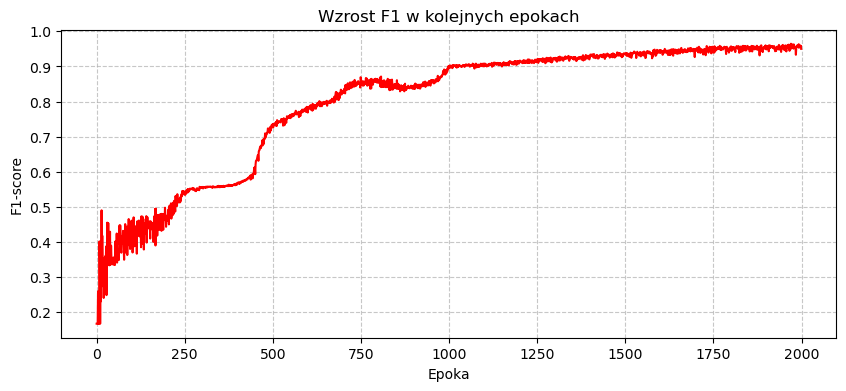

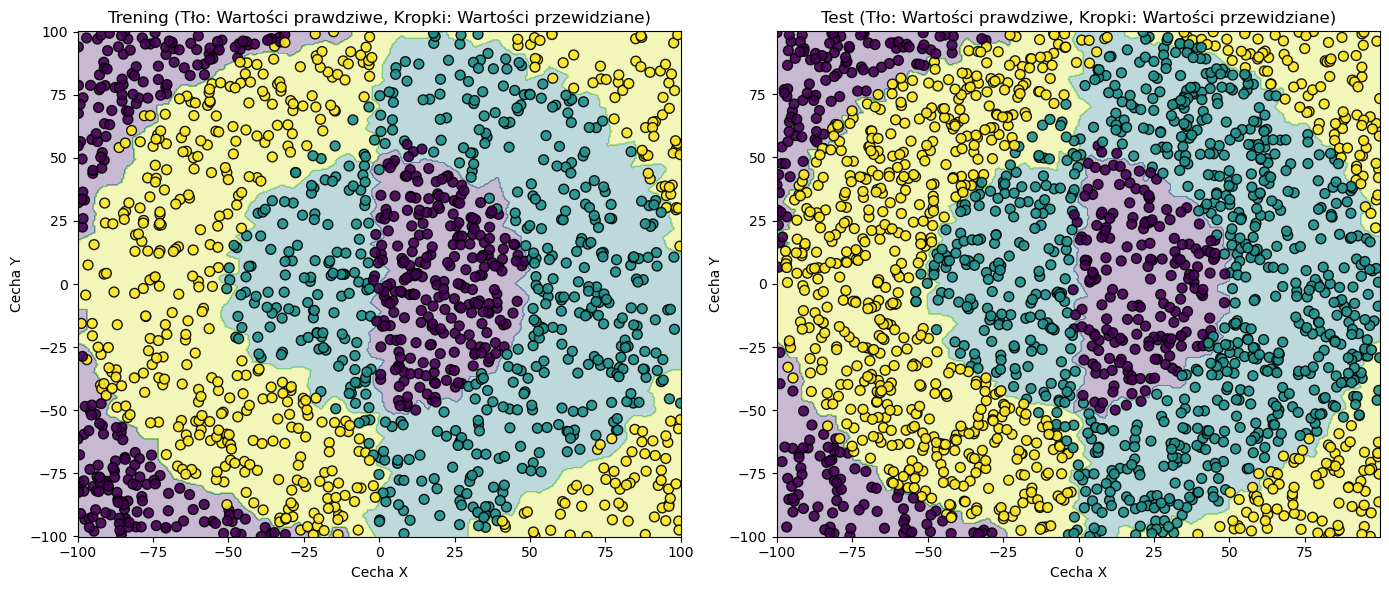

In [41]:
hist = train(X_train, y_train, X_test, y_test, model, 2000, 64, test=True)

In [42]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | F1 Trening:   0.1667
Krok   100 | F1 Trening:   0.5458
Krok   200 | F1 Trening:   0.8609
Krok   300 | F1 Trening:   0.9319
Krok   400 | F1 Trening:   0.9458
Krok   500 | F1 Trening:   0.9449
Krok   600 | F1 Trening:   0.9573
Krok   700 | F1 Trening:   0.9734
Krok   800 | F1 Trening:   0.9753
Krok   900 | F1 Trening:   0.9787
Krok  1000 | F1 Trening:   0.9681
Krok  1100 | F1 Trening:   0.9720
Krok  1200 | F1 Trening:   0.9699
Krok  1300 | F1 Trening:   0.9833
Krok  1400 | F1 Trening:   0.9846
Krok  1500 | F1 Trening:   0.9733
Krok  1600 | F1 Trening:   0.9947
Krok  1700 | F1 Trening:   0.9596
Krok  1800 | F1 Trening:   0.9685
Krok  1900 | F1 Trening:   0.9766
--------------------------------------------------
F1 treningowe FINALNE: 0.9717
F1 testowe FINALNE: 0.9533


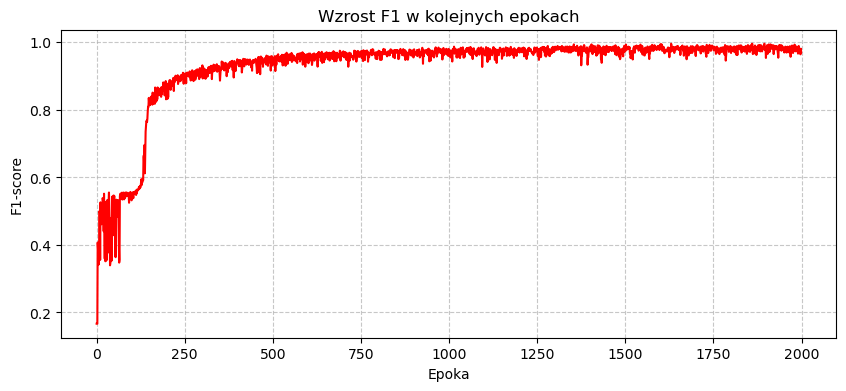

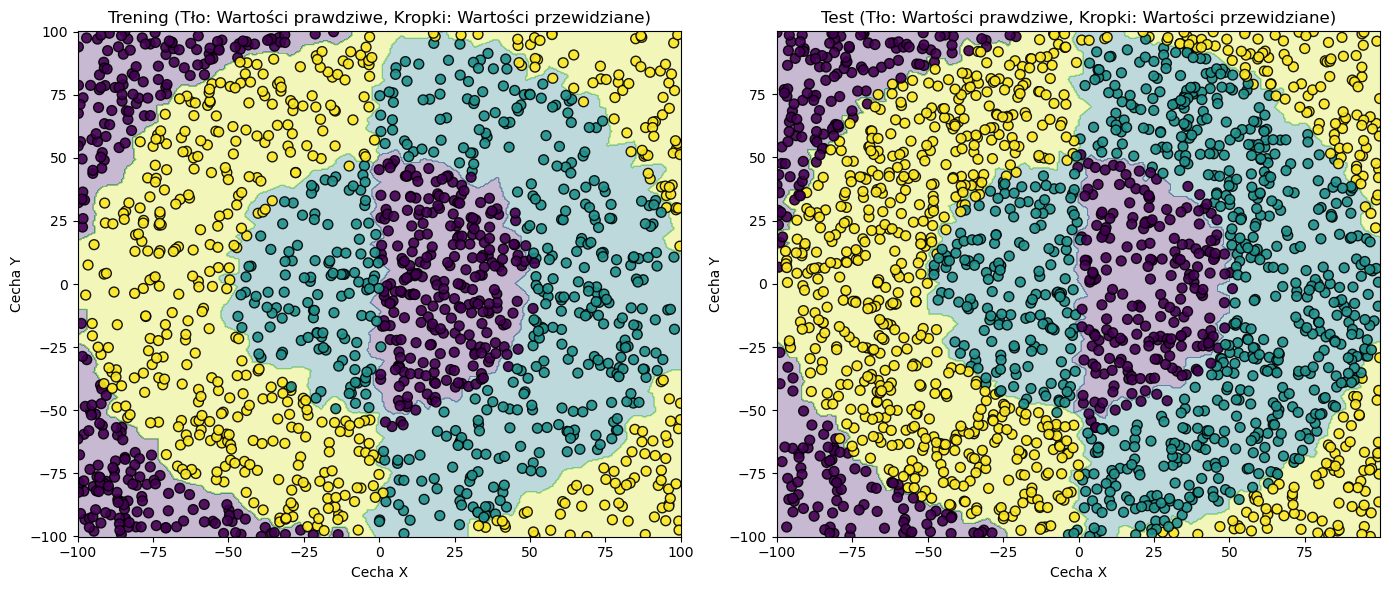

In [43]:
hist_softmax = train(X_train, y_train, X_test, y_test, model, 2000, 64, test=True)

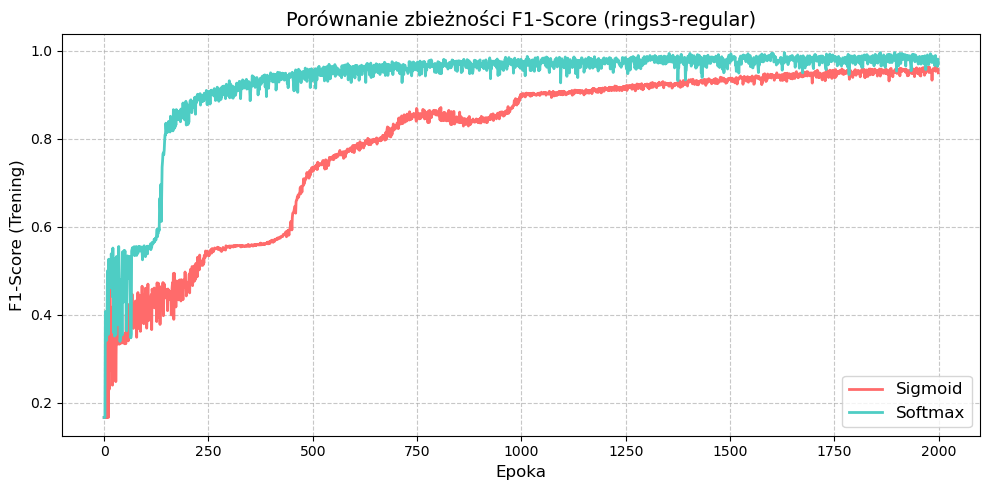

In [44]:
wykres_f1(hist_softmax, hist, 'rings3-regular')

# Dane easy

In [45]:
easy_test = pd.read_csv("mio1/classification/easy-test.csv")
easy_train = pd.read_csv("mio1/classification/easy-training.csv")

X_train = easy_train[['x', 'y']].to_numpy() 
y_train_etykiety = easy_train[['c']].to_numpy().astype(int) 
X_test = easy_test[['x', 'y']].to_numpy()
y_test_etykiety = easy_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [46]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | F1 Trening:   0.3333
Krok   100 | F1 Trening:   0.9940
Krok   200 | F1 Trening:   0.9980
Krok   300 | F1 Trening:   0.9960
Krok   400 | F1 Trening:   0.9960
Krok   500 | F1 Trening:   0.9980
Krok   600 | F1 Trening:   0.9980
Krok   700 | F1 Trening:   0.9960
Krok   800 | F1 Trening:   0.9960
Krok   900 | F1 Trening:   0.9960
--------------------------------------------------
F1 treningowe FINALNE: 0.9940
F1 testowe FINALNE: 0.9920


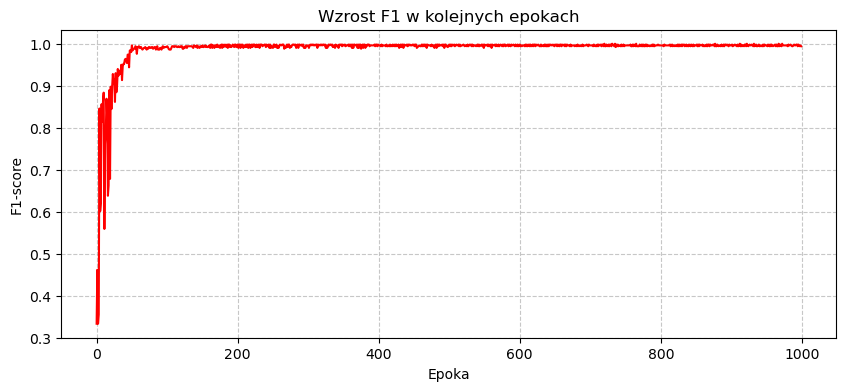

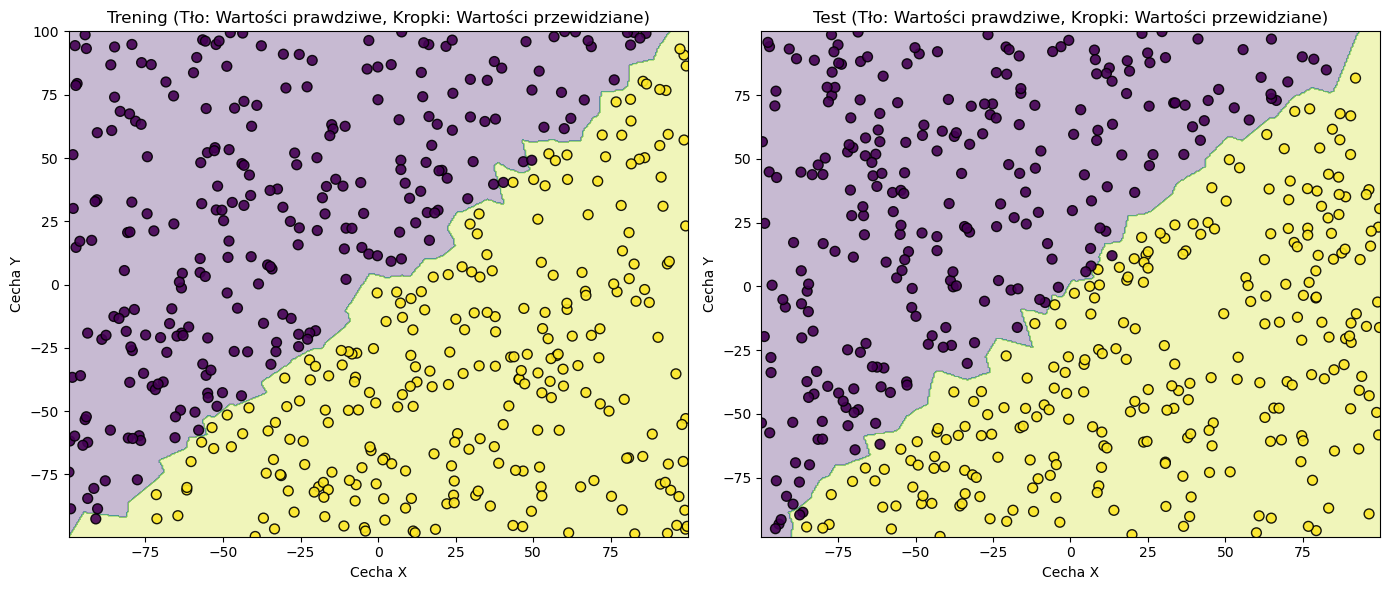

In [47]:
hist = train(X_train, y_train, X_test, y_test, model, 1000, 64, test=True)

In [48]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | F1 Trening:   0.3333
Krok   100 | F1 Trening:   0.9980
Krok   200 | F1 Trening:   0.9860
Krok   300 | F1 Trening:   0.9940
Krok   400 | F1 Trening:   0.9880
Krok   500 | F1 Trening:   1.0000
Krok   600 | F1 Trening:   0.9960
Krok   700 | F1 Trening:   0.9940
Krok   800 | F1 Trening:   0.9940
Krok   900 | F1 Trening:   0.9940
--------------------------------------------------
F1 treningowe FINALNE: 0.9980
F1 testowe FINALNE: 0.9980


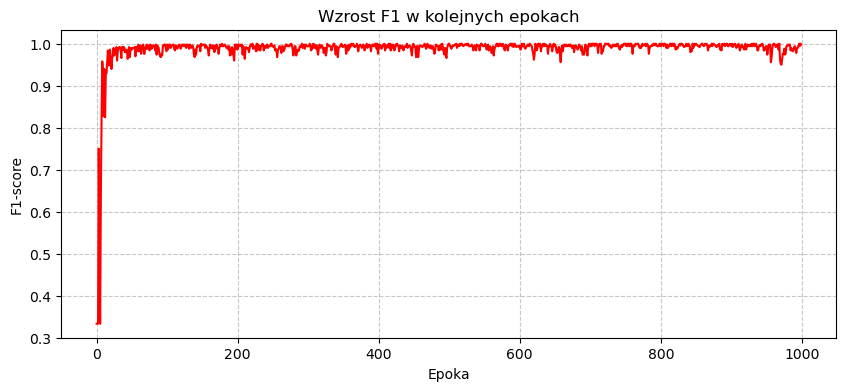

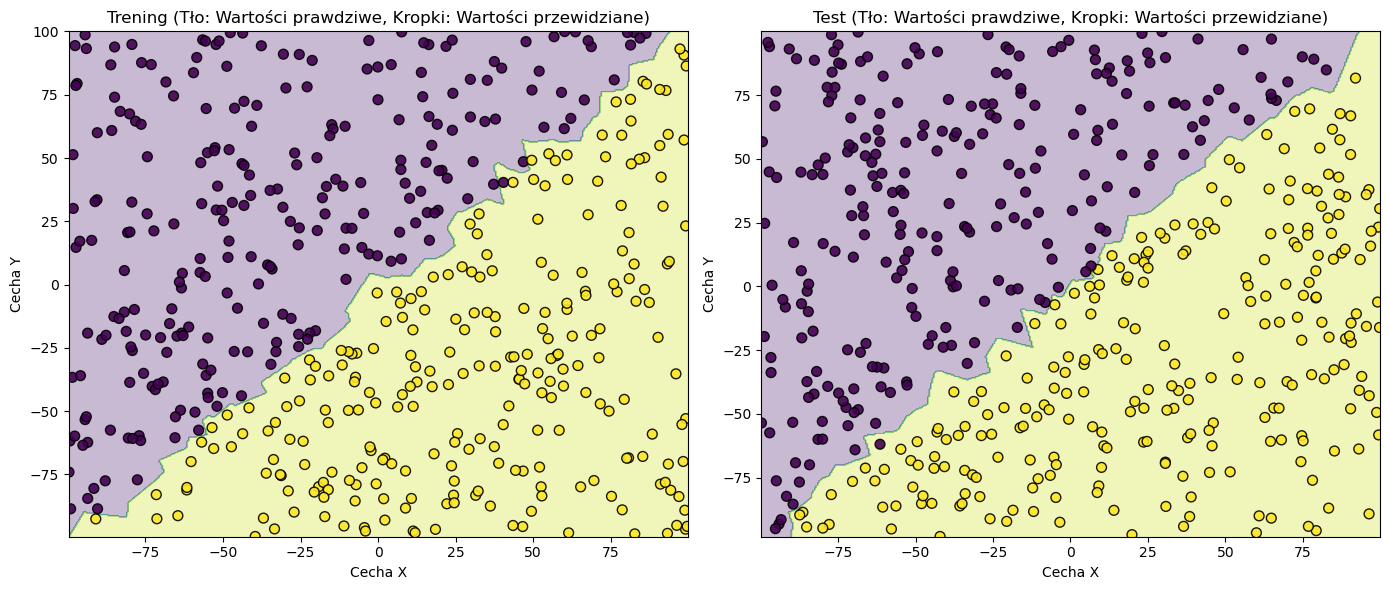

In [49]:
hist_softmax = train(X_train, y_train, X_test, y_test, model, 1000, 64, test=True)

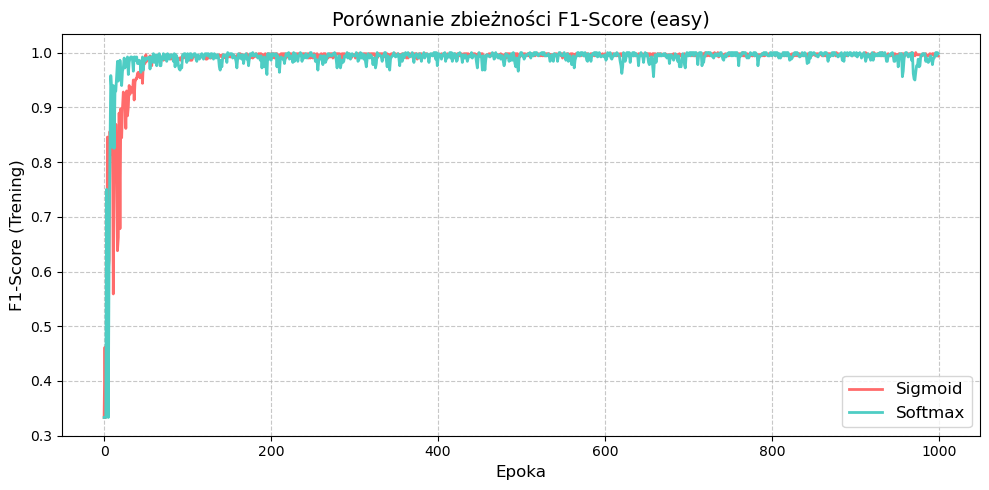

In [50]:
wykres_f1(hist_softmax, hist, 'easy')

# Dane xor3

In [51]:
xor3_test = pd.read_csv("mio1/classification/xor3-test.csv")
xor3_train = pd.read_csv("mio1/classification/xor3-training.csv")

X_train = xor3_train[['x', 'y']].to_numpy() 
y_train_etykiety = xor3_train[['c']].to_numpy().astype(int) 
X_test = xor3_test[['x', 'y']].to_numpy()
y_test_etykiety = xor3_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [52]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, sigmoid()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | F1 Trening:   0.3333
Krok   100 | F1 Trening:   0.3333
Krok   200 | F1 Trening:   0.4890
Krok   300 | F1 Trening:   0.3333
Krok   400 | F1 Trening:   0.4294
Krok   500 | F1 Trening:   0.4407
Krok   600 | F1 Trening:   0.4766
Krok   700 | F1 Trening:   0.4836
Krok   800 | F1 Trening:   0.6036
Krok   900 | F1 Trening:   0.6036
Krok  1000 | F1 Trening:   0.7172
Krok  1100 | F1 Trening:   0.8140
Krok  1200 | F1 Trening:   0.8219
Krok  1300 | F1 Trening:   0.8300
Krok  1400 | F1 Trening:   0.8500
Krok  1500 | F1 Trening:   0.8779
Krok  1600 | F1 Trening:   0.8800
Krok  1700 | F1 Trening:   0.8880
Krok  1800 | F1 Trening:   0.8860
Krok  1900 | F1 Trening:   0.9020
Krok  2000 | F1 Trening:   0.8773
Krok  2100 | F1 Trening:   0.9420
Krok  2200 | F1 Trening:   0.9460
Krok  2300 | F1 Trening:   0.9640
Krok  2400 | F1 Trening:   0.9680
Krok  2500 | F1 Trening:   0.9820
Krok  2600 | F1 Trening:   0.9720
Krok  2700 | F1 Trening:   0.9460
Krok  2800 | F1 Trening:   0.9720
Krok  2900 | F

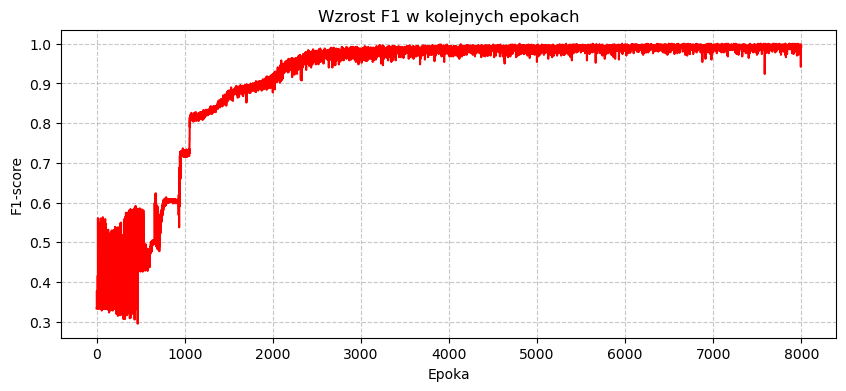

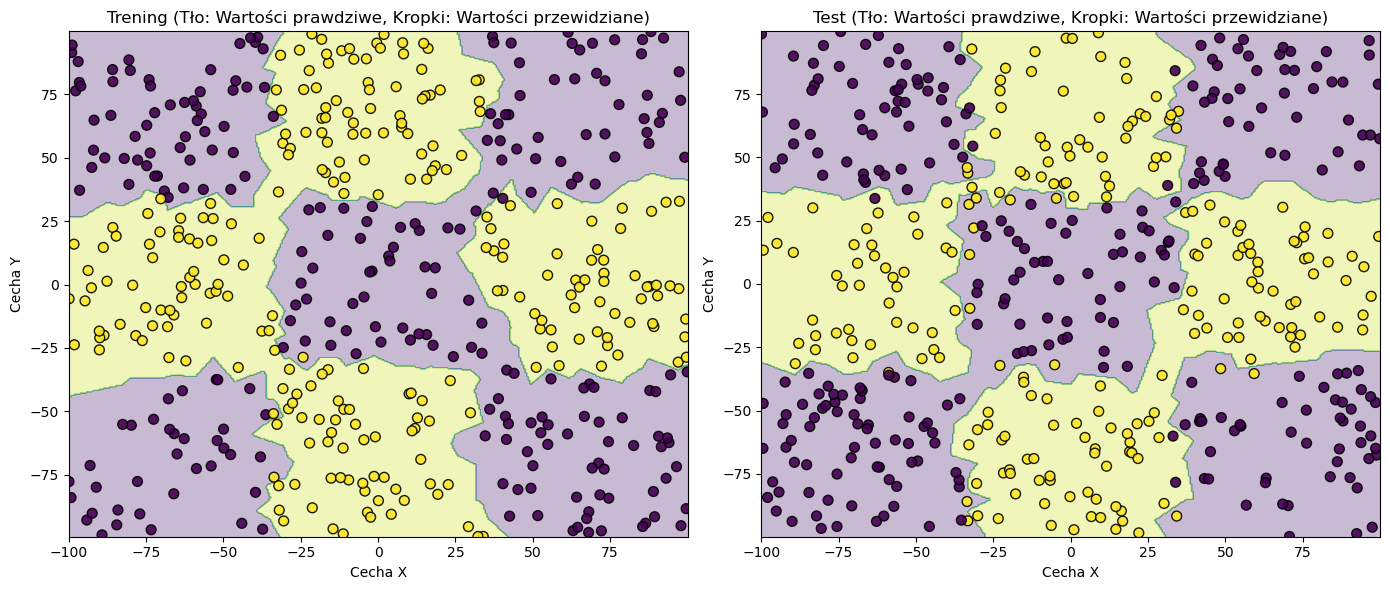

In [53]:
hist = train(X_train, y_train, X_test, y_test, model, 8000, 16, test=True)

In [54]:
warstwa_1 = warstwa_liniowa(2, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, liczba_klas, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3, softmax()), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | F1 Trening:   0.3333
Krok   100 | F1 Trening:   0.3333
Krok   200 | F1 Trening:   0.3333
Krok   300 | F1 Trening:   0.3333
Krok   400 | F1 Trening:   0.5338
Krok   500 | F1 Trening:   0.3552
Krok   600 | F1 Trening:   0.6019
Krok   700 | F1 Trening:   0.7126
Krok   800 | F1 Trening:   0.8578
Krok   900 | F1 Trening:   0.8819
Krok  1000 | F1 Trening:   0.9320
Krok  1100 | F1 Trening:   0.9540
Krok  1200 | F1 Trening:   0.9399
Krok  1300 | F1 Trening:   0.9560
Krok  1400 | F1 Trening:   0.9700
Krok  1500 | F1 Trening:   0.9600
Krok  1600 | F1 Trening:   0.9640
Krok  1700 | F1 Trening:   0.9720
Krok  1800 | F1 Trening:   0.9880
Krok  1900 | F1 Trening:   0.9700
Krok  2000 | F1 Trening:   0.9740
Krok  2100 | F1 Trening:   0.9820
Krok  2200 | F1 Trening:   0.9620
Krok  2300 | F1 Trening:   0.9720
Krok  2400 | F1 Trening:   0.9840
Krok  2500 | F1 Trening:   0.9860
Krok  2600 | F1 Trening:   0.9940
Krok  2700 | F1 Trening:   0.9900
Krok  2800 | F1 Trening:   0.9960
Krok  2900 | F

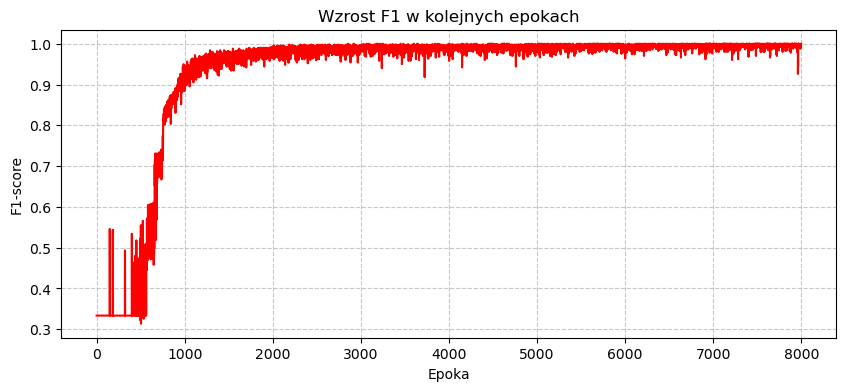

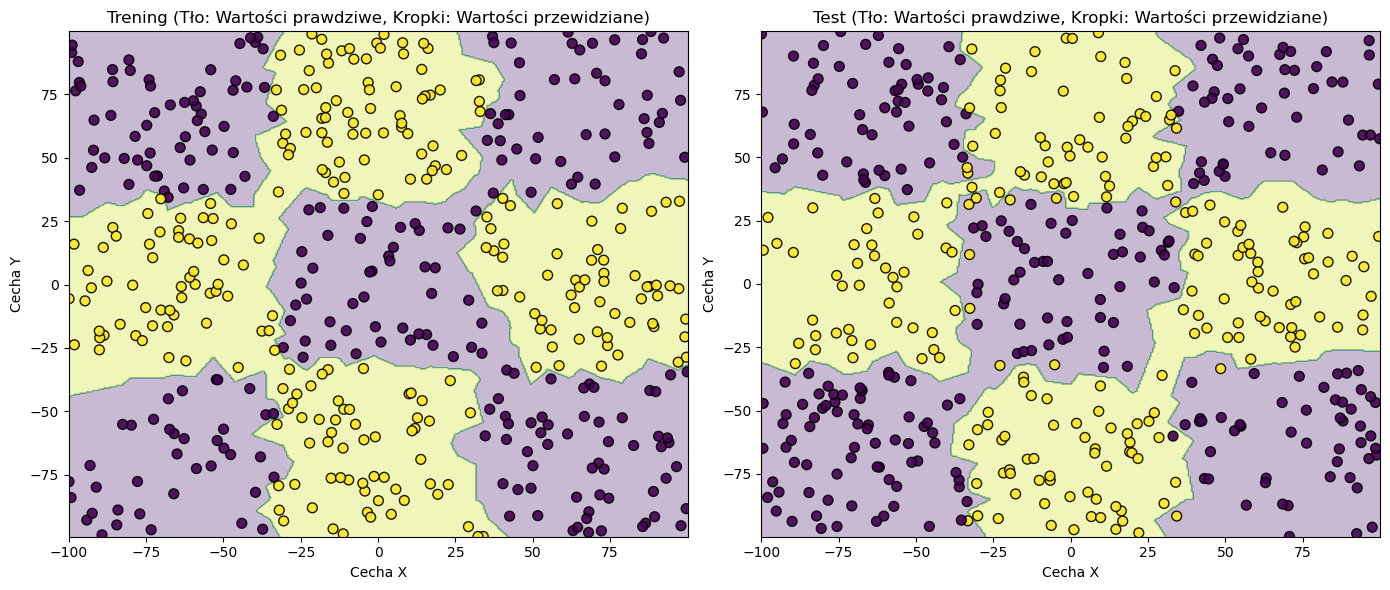

In [55]:
hist_softmax = train(X_train, y_train, X_test, y_test, model, 8000, 16, test=True)

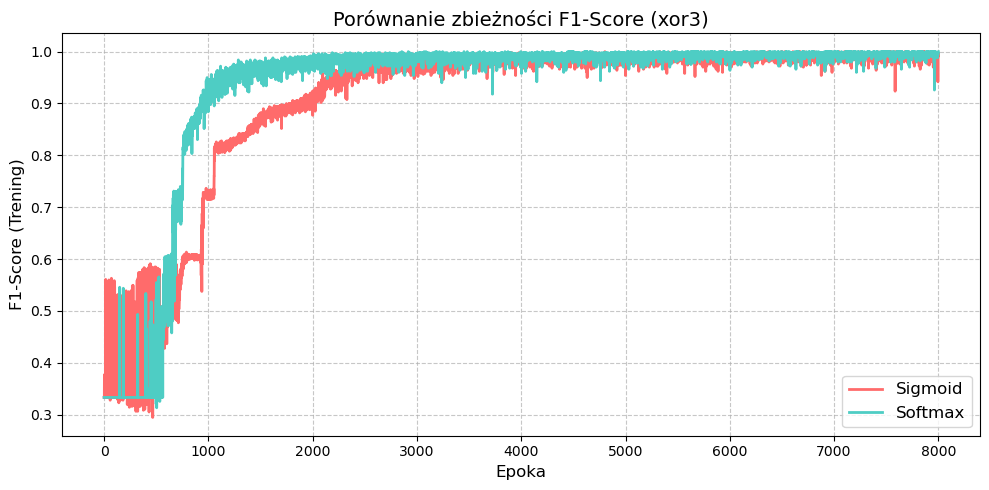

In [56]:
wykres_f1(hist_softmax, hist, 'xor3')